# Project: Online Retail Transaction Analysis
Domain: E-commerce · Data Analytics · Python · Exploratory Data Analysis

#### Business problem statement

An online retail business generates thousands of transactions, but raw transaction data does not directly explain its sales performance, customer purchasing behaviour, product demand or revenue losses caused by cancellations and returns.

Without structured analysis, the business may struggle to identify its best-performing products, most valuable customers, important markets and unusual transaction patterns.

The objective of this project is to analyse a real-world online retail transaction dataset using Python to uncover sales trends, understand customer purchasing behaviour, evaluate product and country performance, and investigate cancellations and potentially unusual transactions.

The analysis will translate raw transactional data into actionable business insights that can support better inventory planning, customer retention and sales decisions.


#### Project objectives

1. Assess and clean the transaction data to improve its reliability.
2. Analyse revenue trends over time and identify important sales periods.
3. Identify top-performing and low-performing products.
4. Understand customer purchasing behaviour and spending patterns.
5. Compare sales performance across countries.
6. Investigate cancelled transactions, returns and unusual records.
7. Develop actionable business recommendations based on the findings.

In [78]:
#Import pandas for loading and analyzing tabular data
import pandas as pd

#Import numpy for numerical operations
import numpy as np

#Import matplotlib for creating charts
import matplotlib.pyplot as plt

#Import seaborn for statistical visulaization
import seaborn as sns

In [79]:
#load excel dataset
df = pd.read_excel("Online Retail.xlsx")

In [80]:
# Display the first five rows to understand the structure of the data
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [81]:
# Get the total number of rows and columns
df.shape

(541909, 8)

In [82]:
# Display all column names available for analysis
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [83]:
# Inspect column data types, non-null counts and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [84]:
# Generate summary statistics for numerical columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [85]:
#Count missing values in each column
missing_count = df.isnull().sum()

#Calculate the percentage of missing values in each column
missing_percentage = (missing_count / len(df)) * 100

#Combine both result into one summary table
missing_summary = pd.DataFrame({
    "Missing_Count" : missing_count,
    "Missing_Percentage" : missing_percentage.round(2)
})

#Display columns with missing values first
missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [86]:
#Identify rows that are exact duplicates of earlier rows
duplicate_count = df.duplicated().sum()

# Display the total number of duplicate rows
print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 5268


In [87]:
#Count transaction with negative quantities
negative_quantity_count = (df["Quantity"] < 0).sum()

#Count transaction with zero quantities
zero_quantity_count = (df["Quantity"] == 0).sum()


# Count transactions with negative unit prices
negative_price_count = (df["UnitPrice"] < 0).sum()

# Count transactions with zero unit prices
zero_price_count = (df["UnitPrice"] == 0).sum()

# Display the results
print("Negative quantities:", negative_quantity_count)
print("Zero quantities:", zero_quantity_count)
print("Negative unit prices:", negative_price_count)
print("Zero unit prices:", zero_price_count)

Negative quantities: 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515


In [88]:
# Convert invoice numbers to strings and identify those starting with C
cancelled_invoice_mask = (
    df["InvoiceNo"].astype(str).str.startswith("C")
)

# Count rows associated with cancellation invoices
cancelled_row_count = cancelled_invoice_mask.sum()

# Count unique cancellation invoice numbers
cancelled_invoice_count = (
    df.loc[cancelled_invoice_mask, "InvoiceNo"].nunique()
)

# Display both results
print("Cancellation rows:", cancelled_row_count)
print("Unique cancellation invoices:", cancelled_invoice_count)

Cancellation rows: 9288
Unique cancellation invoices: 3836


In [89]:
# Select rows where the sold quantity is negative
returns_df = df[df["Quantity"] < 0]

# Display selected columns for the first 10 return-related rows
returns_df[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [90]:
# Identify invoices whose invoice number starts with C
cancellation_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Identify rows with negative quantities
negative_quantity_mask = df["Quantity"] < 0

# Count negative-quantity rows with cancellation invoice numbers
negative_qty_with_c = (
    cancellation_mask & negative_quantity_mask
).sum()

# Count negative-quantity rows without cancellation invoice numbers
negative_qty_without_c = (
    ~cancellation_mask & negative_quantity_mask
).sum()

# Display the comparison
print("Negative quantity rows with C invoices:", negative_qty_with_c)
print("Negative quantity rows without C invoices:", negative_qty_without_c)
print("Total negative quantity rows:", negative_quantity_mask.sum())

Negative quantity rows with C invoices: 9288
Negative quantity rows without C invoices: 1336
Total negative quantity rows: 10624


In [91]:
#create a copy of oroginal dataset 
df = df.copy()

# Calculate transaction value using quantity multiplied by unit price
df["LineTotal"] = df["Quantity"] * df["UnitPrice"]

#Display the oroginal fields alongside the calculated transaction value
df[
    ["InvoiceNo", "Quantity", "UnitPrice", "LineTotal"]
].head(10)


,InvoiceNo,Quantity,UnitPrice,LineTotal
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


In [92]:
# Calculate the total value across all transaction rows
total_line_value = df["LineTotal"].sum()

# Calculate the value of rows with positive transaction amounts
positive_line_value = df.loc[
    df["LineTotal"] > 0, "LineTotal"
].sum()

# Calculate the value of rows with negative transaction amounts
negative_line_value = df.loc[
    df["LineTotal"] < 0, "LineTotal"
].sum()

# Count rows with zero transaction value
zero_value_rows = (df["LineTotal"] == 0).sum()

# Display the results rounded to two decimal places
print("Total line value:", round(total_line_value, 2))
print("Positive line value:", round(positive_line_value, 2))
print("Negative line value:", round(negative_line_value, 2))
print("Zero-value rows:", zero_value_rows)

Total line value: 9747747.93
Positive line value: 10666684.54
Negative line value: -918936.61
Zero-value rows: 2515


In [93]:
# Identify exact duplicate rows, excluding the first occurrence
duplicate_mask = df.duplicated(keep="first")

# Extract the duplicate rows for investigation
duplicates_df = df.loc[duplicate_mask].copy()

# Display the first 10 duplicate records
duplicates_df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom,3.75
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom,2.10
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,1.65
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom,7.50


In [94]:
# Calculate the value contributed by identified duplicate rows
duplicate_value = duplicates_df["LineTotal"].sum()

# Calculate total transaction value before removing duplicates
value_before = df["LineTotal"].sum()

# Create a temporary dataset without exact duplicate rows
df_without_duplicates = df.drop_duplicates()

# Calculate transaction value after removing exact duplicates
value_after = df_without_duplicates["LineTotal"].sum()


# Display the financial impact of duplicate removal
print("Value of duplicate rows:", round(duplicate_value, 2))
print("Total value before removal:", round(value_before, 2))
print("Total value after removal:", round(value_after, 2))
print("Change in value:", round(value_before - value_after, 2))

Value of duplicate rows: 21740.98
Total value before removal: 9747747.93
Total value after removal: 9726006.95
Change in value: 21740.98


In [95]:
# Create a cleaned dataset by removing exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Reset the row index after duplicate removal
df_clean = df_clean.reset_index(drop=True)

# Display the cleaned dataset dimensions
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Confirm that no exact duplicate rows remain
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Original dataset shape: (541909, 9)
Cleaned dataset shape: (536641, 9)
Remaining exact duplicates: 0


In [96]:
# Count missing values in each column of the cleaned dataset
missing_clean = df_clean.isnull().sum()

# Keep only columns that contain missing values
missing_clean = missing_clean[missing_clean > 0]


# Display the remaining missing-value counts
print(missing_clean)

Description      1454
CustomerID     135037
dtype: int64


In [97]:
# Create a copy of the cleaned dataset for sales analysis
sales_df = df_clean.copy()

# Extract the year and month from each invoice date
sales_df["SalesMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Group transactions by month and calculate their net line value
monthly_sales = (
    sales_df.groupby("SalesMonth")["LineTotal"]
    .sum()
    .reset_index()
)

# Convert the monthly period to text for easier display and chart labels
monthly_sales["SalesMonth"] = monthly_sales["SalesMonth"].astype(str)

# Display the first 12 monthly results
monthly_sales.head(12)

,SalesMonth,LineTotal
0,2010-12,746723.610
1,2011-01,558448.560
2,2011-02,497026.410
3,2011-03,682013.980
4,2011-04,492367.841
5,2011-05,722094.100
6,2011-06,689977.230
7,2011-07,680156.991
8,2011-08,681386.460
9,2011-09,1017596.682


In [98]:
# Find the row with the highest monthly net line value
best_month = monthly_sales.loc[
    monthly_sales["LineTotal"].idxmax()
]

# Find the row with the lowest monthly net line value

lowest_month = monthly_sales.loc[
    monthly_sales["LineTotal"].idxmin()
]

# Display the highest month and its value
print("Highest month:", best_month["SalesMonth"])
print("Highest net line value:", round(best_month["LineTotal"], 2))

# Display the lowest month and its value
print("Lowest month:", lowest_month["SalesMonth"])
print("Lowest net line value:", round(lowest_month["LineTotal"], 2))

Highest month: 2011-11
Highest net line value: 1456145.8
Lowest month: 2011-12
Lowest net line value: 432701.06


In [99]:
# Group transactions by product code and description
# Then calculate the net line value generated by each product

product_sales = (
    df_clean.groupby(["StockCode","Description"], dropna = False)["LineTotal"]
    .sum()
    .reset_index()
)

# Sort products from highest to lowest net line value
product_sales = product_sales.sort_values(
    by="LineTotal",
    ascending=False
)

# Display the top 10 products by net line value
product_sales.head(10)

,StockCode,Description,LineTotal
5736,DOT,DOTCOM POSTAGE,206245.48
1810,22423,REGENCY CAKESTAND 3 TIER,164459.49
3544,47566,PARTY BUNTING,98243.88
5280,85123A,WHITE HANGING HEART T-LIGHT HOLDER,97659.94
5266,85099B,JUMBO BAG RED RETROSPOT,92175.79
2690,23084,RABBIT NIGHT LIGHT,66661.63
5740,POST,POSTAGE,66230.64
1424,22086,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
3882,84879,ASSORTED COLOUR BIRD ORNAMENT,58792.42
3654,79321,CHILLI LIGHTS,53746.66


In [100]:
# Group products and add their quantities
product_quantity = df_clean.groupby("Description")["Quantity"].sum()

# Sort products from highest to lowest quantity
product_quantity = product_quantity.sort_values(ascending=False)

# Show the top 10 products
product_quantity.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64

In [101]:
# Group transaction values by country
country_sales = df_clean.groupby("Country")["LineTotal"].sum()

# Sort countries by sales value, highest first
country_sales = country_sales.sort_values(ascending=False)

# Display the top 10 countries
country_sales.head(10)

Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: LineTotal, dtype: float64

In [102]:
# Keep rows where customer ID is available
customer_df = df_clean.dropna(subset=["CustomerID"])

# Group sales value by customer
customer_sales = customer_df.groupby("CustomerID")["LineTotal"].sum()

# Sort customers by sales value
customer_sales = customer_sales.sort_values(ascending=False)

# Display the top 10 customers
customer_sales.head(10)

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: LineTotal, dtype: float64

In [103]:
# Count unique invoice numbers
total_orders = df_clean["InvoiceNo"].nunique()

# Display the total number of unique invoices
print("Total unique invoices:", total_orders)

Total unique invoices: 25900


In [104]:
# Count invoices that start with C (cancellation/credit-note invoices)
cancelled_orders = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]["InvoiceNo"].nunique()

# Calculate invoice count excluding C-prefixed invoices
other_orders = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]["InvoiceNo"].nunique()

# Display both counts
print("Cancellation invoices:", cancelled_orders)
print("Other invoices:", other_orders)

Cancellation invoices: 3836
Other invoices: 22064


In [105]:
# Keep invoices that do not start with C
regular_orders = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Calculate the total line value for each invoice
invoice_values = regular_orders.groupby("InvoiceNo")["LineTotal"].sum()

# Calculate the average value per invoice
average_order_value = invoice_values.mean()

# Display the result
print("Average invoice value:", round(average_order_value, 2))

Average invoice value: 481.33


In [106]:
# Keep transactions with an identified customer
known_customers = df_clean.dropna(subset=["CustomerID"])

# Count unique invoices for each customer
customer_orders = known_customers.groupby("CustomerID")["InvoiceNo"].nunique()

# Sort customers by order count
customer_orders = customer_orders.sort_values(ascending=False)

# Display the top 10 customers by number of invoices
customer_orders.head(10)

CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
13089.0    118
15311.0    118
12971.0     89
14527.0     86
13408.0     81
14646.0     77
Name: InvoiceNo, dtype: int64

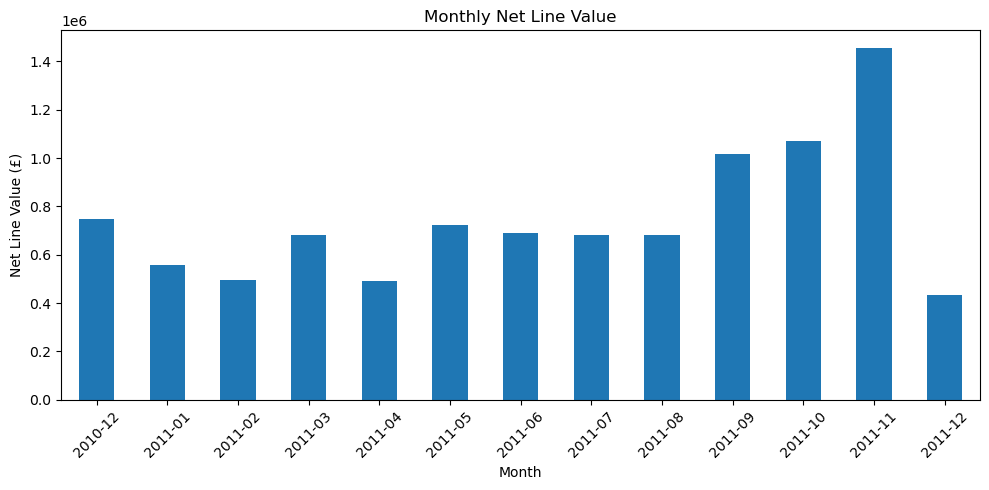

In [107]:
# Convert monthly sales values to a bar chart
monthly_sales.plot(
    x="SalesMonth",
    y="LineTotal",
    kind="bar",
    figsize=(10, 5),
    legend=False,
    title="Monthly Net Line Value"
)

# Add labels to the chart axes
plt.xlabel("Month")
plt.ylabel("Net Line Value (£)")

# Rotate month labels so they are easier to read
plt.xticks(rotation=45)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

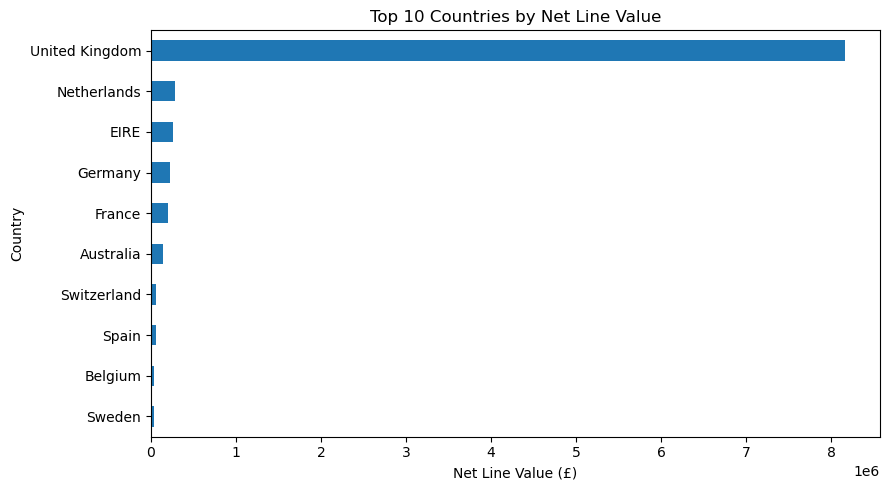

In [108]:
# Select the top 10 countries by net line value
top_countries = country_sales.head(10)

# Create a horizontal bar chart
top_countries.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Countries by Net Line Value"
)

# Label the chart axes
plt.xlabel("Net Line Value (£)")
plt.ylabel("Country")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

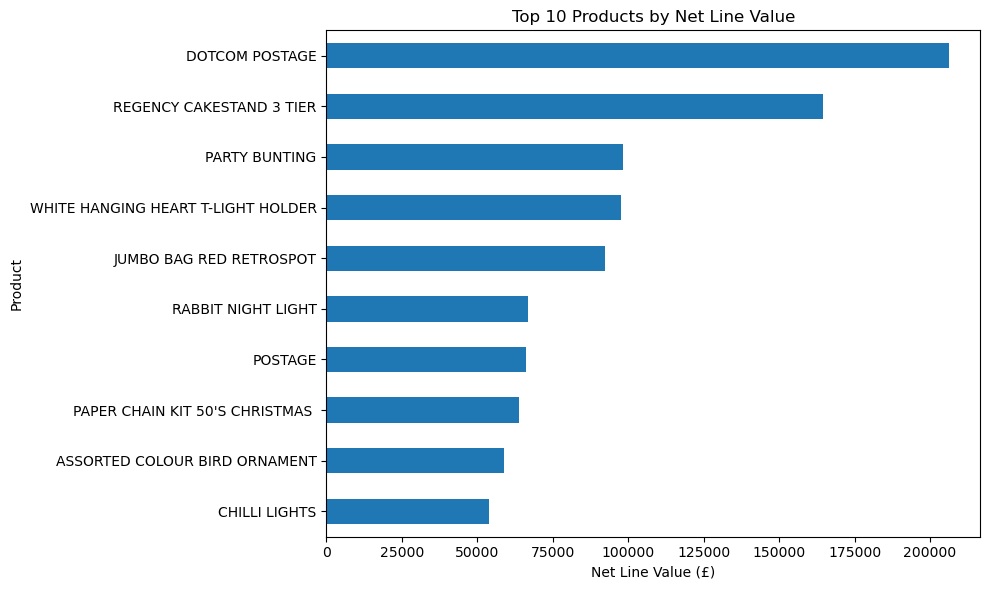

In [109]:
# Select the top 10 products by net line value
top_products = product_sales.head(10)

# Create a horizontal bar chart
top_products.sort_values("LineTotal").plot(
    x="Description",
    y="LineTotal",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="Top 10 Products by Net Line Value"
)

# Label the axes
plt.xlabel("Net Line Value (£)")
plt.ylabel("Product")

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

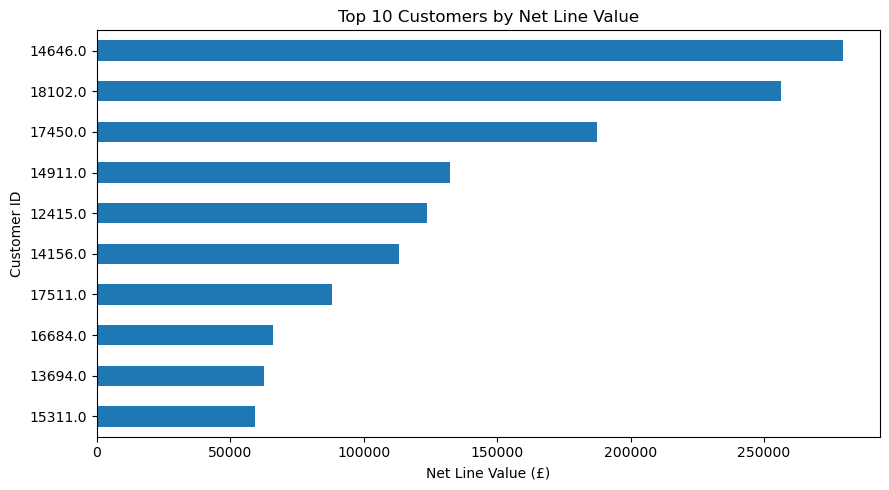

In [110]:
# Select the top 10 customers by net line value
top_customers = customer_sales.head(10)

# Create a horizontal bar chart
top_customers.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Customers by Net Line Value"
)

# Add axis labels
plt.xlabel("Net Line Value (£)")
plt.ylabel("Customer ID")

# Display the chart neatly
plt.tight_layout()
plt.show()

In [111]:
# Create a copy of the cleaned dataset for weekday analysis
weekday_df = df_clean.copy()

# Extract the weekday name from each invoice date
weekday_df["Weekday"] = weekday_df["InvoiceDate"].dt.day_name()

# Arrange weekdays in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate net line value for each weekday
weekday_sales = weekday_df.groupby("Weekday")["LineTotal"].sum()

# Arrange the results in weekday order
weekday_sales = weekday_sales.reindex(weekday_order)

# Display the weekday results
weekday_sales

Weekday
Monday       1584895.301
Tuesday      1965703.611
Wednesday    1730088.430
Thursday     2108701.530
Friday       1537958.621
Saturday             NaN
Sunday        798659.461
Name: LineTotal, dtype: float64

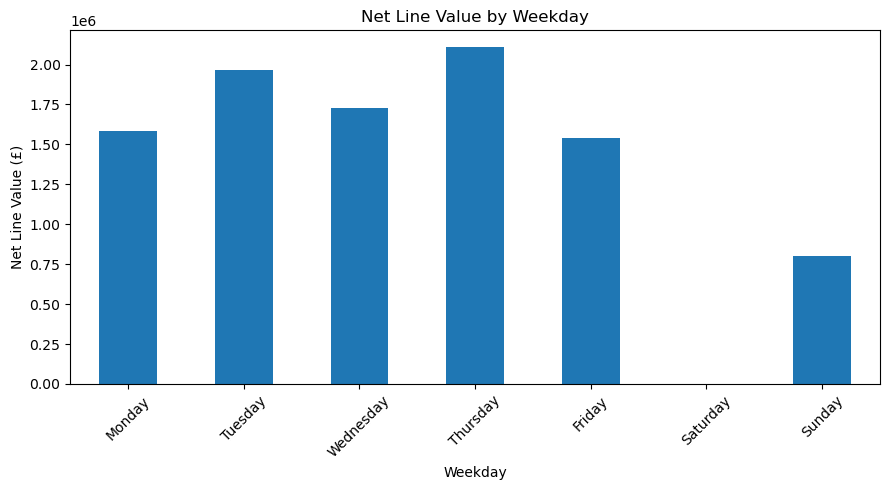

In [112]:
# Create a bar chart of net line value by weekday
weekday_sales.plot(
    kind="bar",
    figsize=(9, 5),
    title="Net Line Value by Weekday"
)

# Label the chart axes
plt.xlabel("Weekday")
plt.ylabel("Net Line Value (£)")

# Rotate weekday labels for readability
plt.xticks(rotation=45)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

In [113]:
# Create a summary of the key findings from our analysis
business_insights = pd.DataFrame({
    "Business Question": [
        "Which month had the highest net line value?",
        "Which country generated the highest net line value?",
        "Which product had the highest net line value?",
        "Which customer generated the highest net line value?",
        "Which weekday had the highest net line value?",
        "How many unique invoices were recorded?",
        "How many invoices started with C?"
    ],
    "Finding": [
        "November 2011",
        "United Kingdom",
        "DOTCOM POSTAGE",
        "Customer 14646",
        "Thursday",
        "25,900",
        "3,836"
    ]
})

# Display the business insights table
business_insights

,Business Question,Finding
0,Which month had the highest net line value?,November 2011
1,Which country generated the highest net line v...,United Kingdom
2,Which product had the highest net line value?,DOTCOM POSTAGE
3,Which customer generated the highest net line ...,Customer 14646
4,Which weekday had the highest net line value?,Thursday
5,How many unique invoices were recorded?,"25,900"
6,How many invoices started with C?,"3,836"
